# Lending Club: does a decision model make XGBoost better at predicting loan default?

We compare three ways of predicting which personal loans will be charged off, on Lending Club's public
loan data:

| Approach | What it uses |
| --- | --- |
| **XGBoost** | The application fields of each loan |
| **TF-IDF** | Only the words the borrower wrote, as a text model trained on the same loans |
| **XGBoost + TF-IDF** | The XGBoost score, plus the TF-IDF text score |
| **XGBoost + Jev** | The XGBoost score, plus Jev's (TypeSafe) answers to underwriter questions about each loan |
| **XGBoost + Grayson** | The XGBoost score, plus Grayson's (Finic) answers to the same questions |

Jev and Grayson read each application, including the borrower's own description of why they need the
loan, and never see whether it was repaid. The metric is ROC-AUC (0.5 is chance, 1.0 is perfect), on
loans issued after every loan used for fitting.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

from fraudbench import api, data
from fraudbench import questions as qs

# API and Kaggle keys come from the environment or a git-ignored .env file. Without API keys, the
# cached answers in data/api_responses/ are used.
if Path(".env").exists():
    for line in Path(".env").read_text().splitlines():
        k, sep, v = line.partition("=")
        if sep and not line.lstrip().startswith("#"):
            os.environ.setdefault(k.strip(), v.strip().strip('"'))

SEED = 2026
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data

Completed Lending Club personal loans issued from 2007 to 2016 whose application includes the
borrower's own description of the loan: about 126,000 loans. A loan counts as a default if it
was charged off. The notebook downloads Lending Club's accepted-loans file (about 1.6 GB) from Kaggle
with `kagglehub` on first run.

The loans are split by issue month, like a lender would use them: the earliest 70% train XGBoost, the
next 10% are the validation period, and the latest 20% are the test period. Jev and Grayson answer a
sample of 2,000 validation loans (300 defaults) and 3,000 test loans (500 defaults). Every approach is
scored on the same 3,000 test loans.

In [2]:
df = data.assign_split(data.load())
df = df[df.split != "unused"].reset_index(drop=True)
y = df[data.LABEL].values
masks = {s: (df.split == s).values for s in ("train", "val", "test")}
rates = {s: y[masks[s]].mean() for s in masks}

val_ids = data.stratified_sample(df[masks["val"]], n_fraud=300, n_total=2000, seed=SEED)
test_ids = data.stratified_sample(df[masks["test"]], n_fraud=500, n_total=3000, seed=SEED)
by_id = df.set_index("id")
y_val, y_test = by_id.loc[val_ids, data.LABEL].values, by_id.loc[test_ids, data.LABEL].values
w_val = qs.prevalence_weights(y_val, rates["val"])   # the samples over-represent defaults; reweight to the true rate
pd.DataFrame({"loans": [masks[s].sum() for s in masks], "default rate": [rates[s] for s in masks],
              "first issued": [df.loc[masks[s], data.DATE].min().date() for s in masks],
              "last issued": [df.loc[masks[s], data.DATE].max().date() for s in masks]}, index=list(masks))

,loans,default rate,first issued,last issued
train,84242,0.1567,2007-06-01,2013-06-01
val,13027,0.1512,2013-07-01,2013-09-01
test,28431,0.1549,2013-10-01,2016-08-01


## 2. XGBoost

Trained on every loan in the training period, with early stopping on the validation period. It sees
the application fields: amount, term, rate and Lending Club grade, employment, income, home ownership,
debt-to-income, credit history and the length of the description.

In [3]:
X = data.tabular_features(df)
model = xgb.XGBClassifier(n_estimators=5000, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.7,
                          tree_method="hist", eval_metric="aucpr", early_stopping_rounds=200, random_state=SEED, n_jobs=-1)
model.fit(X[masks["train"]], y[masks["train"]], eval_set=[(X[masks["val"]], y[masks["val"]])], verbose=False)
df["p_xgb"] = model.predict_proba(X)[:, 1]
by_id = df.set_index("id")
print(f"best iteration {model.best_iteration}")

best iteration 309


### TF-IDF: a traditional model that reads the borrower's words

The standard way to put text into a credit model: a TF-IDF logistic regression over everything the
borrower wrote (the description, the loan title and the job title), trained on the training period,
with its regularization chosen on the validation period. It shows how much a traditional text model
gets out of the same words Grayson and Jev read.

In [4]:
texts = data.text(df)
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, max_features=100_000, sublinear_tf=True,
                        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
T_train = tfidf.fit_transform(texts[masks["train"]])
T = tfidf.transform(texts)
best = None
for C in (0.25, 1.0, 4.0):
    text_model = LogisticRegression(C=C, max_iter=2000).fit(T_train, y[masks["train"]])
    score = average_precision_score(y[masks["val"]], text_model.predict_proba(T[masks["val"]])[:, 1])
    if best is None or score > best[0]:
        best = (score, C, text_model)
df["p_text"] = best[2].predict_proba(T)[:, 1]
by_id = df.set_index("id")
del T, T_train
print(f"TF-IDF: C={best[1]}")

TF-IDF: C=0.25


## 3. The questions and the API answers

27 questions an underwriter might ask about an application, such as whether the stated income is
plausible for the job title, whether the description matches the loan's purpose, and whether the
borrower describes financial hardship. Four are graded on a five-level scale instead of yes or no.
They were written before any results.

Each sampled loan goes to Jev and Grayson once with all 27 questions: the application fields as
structured data, and the borrower's description as free text. Each answer becomes a log-odds feature,
standardized on the validation loans.

In [5]:
pd.Series({k: v[1] for k, v in qs.POOL.items()}, name="question").to_frame()

,question
income_plausible_for_job,Is the stated annual income plausible for this...
income_inflated,Does the stated income look inflated for this ...
job_title_real,"Does the job title look like a real, specific ..."
stable_job,"Does the job title suggest stable, steady empl..."
income_low_for_area,Is the income low relative to the cost of livi...
desc_matches_purpose,Does the borrower's description match the stat...
desc_repayment_plan,"Does the description lay out a specific, credi..."
desc_genuine,Does the description read like a genuine perso...
desc_evasive,"Is the description evasive, or inconsistent wi..."
hardship,Does the borrower describe current financial h...


In [6]:
contexts = {s: {int(i): qs.context(by_id.loc[i], data.build_context) for i in ids}
            for s, ids in (("val", val_ids), ("test", test_ids))}
ANSWERS = {}
for client, label in ((qs.Jev(), "Jev"), (qs.Grayson(), "Grayson")):
    feats = {s: qs.answer_features(api.query(client, contexts[s], qs.POOL, s)) for s in contexts}
    mu, sd = feats["val"].mean(), feats["val"].std()
    ANSWERS[label] = {s: (f - mu) / sd for s, f in feats.items()}
{label: a["test"].shape for label, a in ANSWERS.items()}

{'Jev': (3000, 31), 'Grayson': (3000, 31)}

## 4. Results

For each decision model, a forward selection on the 2,000 validation loans picks which of its answers
add to the XGBoost score (adding one at a time while the cross-validated AUC improves), and a small
logistic layer combines them with the XGBoost score. XGBoost + TF-IDF uses the same kind of
layer over the XGBoost and TF-IDF scores. Both are fitted on validation and frozen, then
scored once on the 3,000 test loans. Brackets are 95% intervals from 1,000 paired bootstrap resamples.

In [7]:
x_val, x_test = qs.logit(by_id.loc[val_ids, "p_xgb"].values), qs.logit(by_id.loc[test_ids, "p_xgb"].values)
scores = {"XGBoost": by_id.loc[test_ids, "p_xgb"].values, "TF-IDF": by_id.loc[test_ids, "p_text"].values}
t_val, t_test = qs.logit(by_id.loc[val_ids, "p_text"].values), qs.logit(by_id.loc[test_ids, "p_text"].values)
text_layer = LogisticRegression(C=1.0, max_iter=5000).fit(np.column_stack([x_val, t_val]), y_val, sample_weight=w_val)
scores["XGBoost + TF-IDF"] = text_layer.predict_proba(np.column_stack([x_test, t_test]))[:, 1]
selected = {}
for label, A in ANSWERS.items():
    picked, _ = qs.forward_select(A["val"], y_val, w_val, SEED, prefix=x_val)
    selected[label] = [qs.POOL[c.split("@")[0]][1] for c in picked]
    layer = LogisticRegression(C=1.0, max_iter=5000).fit(np.column_stack([x_val, A["val"][picked].values]), y_val, sample_weight=w_val)
    scores[f"XGBoost + {label}"] = layer.predict_proba(np.column_stack([x_test, A["test"][picked].values]))[:, 1]

boot = np.random.default_rng(SEED).integers(0, len(y_test), size=(1000, len(y_test)))
base = scores["XGBoost"]
rows = {}
for label, p in scores.items():
    row = {"ROC-AUC": roc_auc_score(y_test, p), "answers added": "; ".join(selected.get(label.split(" + ")[-1], [])) or "\u2014"}
    if label != "XGBoost":
        d = np.array([roc_auc_score(y_test[i], p[i]) - roc_auc_score(y_test[i], base[i]) for i in boot])
        row["vs XGBoost"] = f"{row['ROC-AUC'] - roc_auc_score(y_test, base):+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]"
    rows[label] = row
results = pd.DataFrame(rows).T[["ROC-AUC", "vs XGBoost", "answers added"]].fillna("\u2014")
results.to_csv(RESULTS / "results.csv")
results

,ROC-AUC,vs XGBoost,answers added
XGBoost,0.6809,—,—
TF-IDF,0.5820,"-0.0989 [-0.1310, -0.0642]",—
XGBoost + TF-IDF,0.6845,"+0.0036 [-0.0025, +0.0101]",—
XGBoost + Jev,0.6871,"+0.0062 [-0.0032, +0.0156]",Does the borrower describe current financial h...
XGBoost + Grayson,0.6888,"+0.0079 [+0.0007, +0.0158]",Does the borrower describe current financial h...


## 5. What it is worth

Every loan in this data was one Lending Club approved. Suppose the lender had also used the model to
decline the riskiest share of those loans. A better ranking means more of the declined loans are ones
that would have been charged off, and fewer are good loans turned away. The dollar values come from
the test period's actual loans: the net loss on a charged-off loan is the amount funded minus
everything repaid (including recoveries), and the profit on a repaid loan is everything repaid minus
the amount funded. Counts are per 10,000 loans at the test period's true default rate.

In [8]:
raw_path = sorted(data.RAW_DIR.glob("**/accepted_2007_to_2018*.csv*"))[0]
pay = pd.read_csv(raw_path, usecols=["id", "funded_amnt", "total_pymnt", "loan_status"], dtype={"id": str}, low_memory=False)
pay = pay[pd.to_numeric(pay["id"], errors="coerce").notna()].assign(id=lambda d: d["id"].astype("int64"))
pay = pay[pay["id"].isin(set(df.loc[masks["test"], "id"]))].set_index("id")
charged = pay["loan_status"].str.contains("Charged Off")
loss = (pay.loc[charged, "funded_amnt"] - pay.loc[charged, "total_pymnt"]).mean()
profit = (pay.loc[~charged, "total_pymnt"] - pay.loc[~charged, "funded_amnt"]).mean()
print(f"average loan ${pay['funded_amnt'].mean():,.0f}; net loss per charge-off ${loss:,.0f}; "
      f"profit per repaid loan ${profit:,.0f}; value of each swap ${loss + profit:,.0f}")

w_test = qs.prevalence_weights(y_test, rates["test"])
roi = []
for declined in (0.10, 0.20, 0.30, 0.50):
    share = 1 - declined   # share of loans kept
    base_bad = qs.bad_per_10k(y_test, w_test, scores["XGBoost"], share)
    for label in ("XGBoost + TF-IDF", "XGBoost + Jev", "XGBoost + Grayson"):
        fewer = base_bad - qs.bad_per_10k(y_test, w_test, scores[label], share)
        roi.append({"riskiest declined": f"{declined:.0%}", "approach": label, "fewer defaults per 10,000 loans": round(fewer, 1),
                    "gain per 10,000 loans ($)": round(fewer * (loss + profit))})
roi = pd.DataFrame(roi).set_index(["riskiest declined", "approach"])
roi.to_csv(RESULTS / "roi.csv")
roi.style.format({"fewer defaults per 10,000 loans": "{:.1f}", "gain per 10,000 loans ($)": "${:,.0f}"})

average loan $15,144; net loss per charge-off $5,114; profit per repaid loan $3,207; value of each swap $8,322


## 6. ROC curves

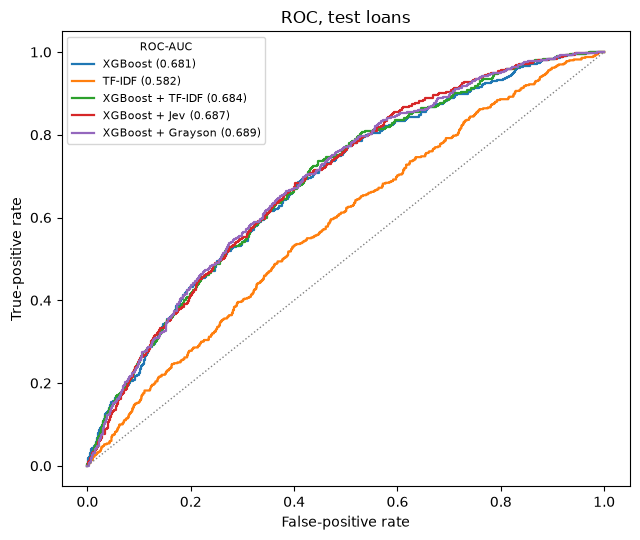

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for label, p in scores.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=1.6, label=f"{label} ({results.loc[label, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC, test loans")
ax.legend(fontsize=8, title="ROC-AUC", title_fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "roc.png", dpi=150)